# Predicting late condition sign-offs

**Question:** on the day a developer submits an application to discharge a planning condition, can we tell whether the council will miss the 8-week (56-day) deadline?

**Target variable:** `late` = 1 if the decision took more than 56 days, 0 otherwise. About half of applications are late, so the two classes are balanced.

**The one rule:** the model may only use what is known **on the day the application is submitted**. Anything that is only known later (the decision, the decision date, comments that pile up while it is being decided) would let the model cheat.

**Steps**
1. Load the data
2. Define the target
3. Build features known at submission
4. Split by time: train on 2021–2023, test on 2024–2025
5. Baselines, then logistic regression, then LightGBM
6. What drives lateness
7. What this does and doesn't show

## 1 · Load the data

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # run from notebooks/: make src/ importable
from conditions_queue import paths

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 140)
PARQUET = paths.PARQUET
DISCHARGE_CSV = paths.DISCHARGE_CSV   # written by src/conditions_queue/analysis.py
STAT_DAYS = 56

# analysis.py already picked out the 17,079 discharge applications and pulled
# topics, number of conditions, number of homes and the parent permission out of the descriptions
dis_all = pd.read_csv(DISCHARGE_CSV, parse_dates=["start_date", "decided_date", "parent_date"])

# a few extra columns from the raw parquet
raw = pd.read_parquet(PARQUET, columns=["name", "app_type", "app_size", "agent_company", "description", "fetched_at"])
d = dis_all.merge(raw, on="name", how="left")
d["fetched_at"] = pd.to_datetime(d["fetched_at"]).dt.tz_localize(None)
print(f"{len(d):,} discharge applications")
d[["name", "area_name", "start_date", "days_to_decision", "outcome", "n_cond", "homes", "topics"]].head()

17,079 discharge applications


,name,area_name,start_date,days_to_decision,outcome,n_cond,homes,topics
0,Barking/22/01014/REM,Barking and Dagenham,2022-06-10,194.0,approved,1,935.0,"Landscaping & trees|Waste, cycle & parking|Hig..."
1,Barking/22/02130/REM,Barking and Dagenham,2022-12-12,88.0,approved,1,3502.0,"Landscaping & trees|Energy & carbon|Waste, cyc..."
2,Barking/24/00868/AOD,Barking and Dagenham,2024-06-13,NaN,approved,2,1000.0,"Landscaping & trees|Waste, cycle & parking"
3,Barnet/24/2686/OUT,Barnet,2024-07-08,NaN,pending,1,365.0,"Landscaping & trees|Waste, cycle & parking|Pil..."
4,Bexley/12/01848/FUL04,Bexley,2021-03-09,20.0,approved,1,NaN,"Waste, cycle & parking"


## 2 · Define the target

- **Decided** applications (approved, refused, part-approved): `late = days_to_decision > 56`.
- **Still undecided** when the data was fetched (August 2026): they have already missed the deadline, so `late = 1`. Dropping them would hide the slowest cases.
- **Withdrawn** applications are dropped: they never got a decision.
- Only applications submitted **2021–2025**.

In [2]:
d = d[d["outcome"].isin(["approved", "refused", "partial", "pending"]) & (d["start_date"].dt.year >= 2021)].copy()
age_at_fetch = (d["fetched_at"] - d["start_date"]).dt.days
decided = d["outcome"] != "pending"
d = d[(decided & (d["days_to_decision"] >= 0)) | (~decided & (age_at_fetch > STAT_DAYS))].copy()

d["late"] = np.where(d["outcome"] == "pending", 1, (d["days_to_decision"] > STAT_DAYS).astype(int))

print(f"Applications in the model: {len(d):,}")
print(f"Still undecided (counted as late): {(d['outcome'] == 'pending').sum():,}")
print(f"Share late: {d['late'].mean():.1%}")

Applications in the model: 16,284
Still undecided (counted as late): 854
Share late: 56.2%


This is a little higher than the 54% on the page, because the page only counts decided applications. Here the undecided ones count as late too.

## 3 · Build features known at submission

**Used:**

| Feature | What it is |
|---|---|
| `area_name` | Borough |
| `app_type`, `app_size` | How the council registered the application |
| `band`, `log_homes` | Scheme size (from the description) |
| `n_cond_c` | Number of conditions bundled in one application (capped at 10) |
| topic flags, `n_topics`, `any_precommencement` | What the conditions are about: drainage, logistics, materials and so on |
| `has_parent`, `lag_days` | Whether we found the original permission, and days since it was granted |
| `month`, `dow` | When it was submitted |
| `desc_words`, `has_agent` | Length of the description, and whether a planning agent is named |
| `boro_workload_28d` | How many discharge applications the borough received in the previous 4 weeks |
| `boro_late_rate_365d` | Borough's late rate over the previous year, using only decisions made **before** this submission |
| `scheme_prior_apps`, `scheme_prior_refusal` | How many times this scheme has already come back, and whether one was refused before |

**Not used, because they leak the answer:** `decided_date`, `days_to_decision`, `decision`, `status`, `decided_by`, `n_comments`, `n_documents`, `last_changed`, and `target_decision_date` (some boroughs move it when an extension is agreed).

In [3]:
slug = lambda t: "t_" + re.sub(r"[^a-z0-9]+", "_", t.lower()).strip("_")
TOPICS = sorted({t for s in d["topics"].dropna() for t in s.split("|")})
topic_lists = d["topics"].fillna("").str.split("|")
for t in TOPICS:
    d[slug(t)] = topic_lists.apply(lambda s: t in s).astype(int)
TOPIC_COLS = [slug(t) for t in TOPICS]

PRE_START = ["Construction logistics / management", "Contamination & ground", "Archaeology & heritage",
             "Drainage & flood", "Piling & structure", "Landscaping & trees"]
d["n_topics"] = d[TOPIC_COLS].sum(axis=1)
d["any_precommencement"] = d[[slug(t) for t in PRE_START]].max(axis=1)
d["log_homes"] = np.log1p(d["homes"])
d["homes_known"] = d["homes"].notna().astype(int)
d["n_cond_c"] = d["n_cond"].clip(upper=10)
d["has_parent"] = d["parent_uid"].notna().astype(int)
d["lag_days"] = d["lag"].clip(upper=3650)
d["month"] = d["start_date"].dt.month
d["dow"] = d["start_date"].dt.dayofweek
d["desc_words"] = d["description"].fillna("").str.split().str.len()
d["has_agent"] = (d["agent_company"].fillna("") != "").astype(int)
for c in ["app_type", "app_size"]:
    d[c] = d[c].replace("", "Unknown").fillna("Unknown")
d["band"] = d["band"].fillna("Unknown")

### Features that look back in time

These use **only** applications submitted or decided **before** each application's own start date, so nothing from the future leaks in. They use every discharge application, including withdrawn ones, because those still took up the council's time.

In [4]:
by_borough = {b: g for b, g in dis_all.groupby("area_name")}
by_scheme = {p: g for p, g in dis_all[dis_all["parent_uid"].notna()].groupby("parent_uid")}
month, year = pd.Timedelta(days=28), pd.Timedelta(days=365)

workload, late_rate, prior_apps, prior_refusal = [], [], [], []
for r in d.itertuples():
    g, s = by_borough[r.area_name], r.start_date
    workload.append(((g["start_date"] < s) & (g["start_date"] >= s - month)).sum())
    past = g[(g["decided_date"] < s) & (g["decided_date"] >= s - year) & g["days_to_decision"].notna()]
    late_rate.append((past["days_to_decision"] > STAT_DAYS).mean() if len(past) >= 20 else np.nan)
    pg = by_scheme.get(r.parent_uid) if isinstance(r.parent_uid, str) else None
    if pg is None:
        prior_apps.append(0); prior_refusal.append(0)
    else:
        prior_apps.append((pg["start_date"] < s).sum())
        prior_refusal.append(int(((pg["decided_date"] < s) & pg["outcome"].isin(["refused", "partial"])).any()))

d["boro_workload_28d"], d["boro_late_rate_365d"] = workload, late_rate
d["scheme_prior_apps"], d["scheme_prior_refusal"] = prior_apps, prior_refusal

CAT = ["area_name", "app_type", "app_size", "band"]
NUM = ["n_cond_c", "n_topics", "any_precommencement", "log_homes", "homes_known", "has_parent", "lag_days",
       "month", "dow", "desc_words", "has_agent", "boro_workload_28d", "boro_late_rate_365d",
       "scheme_prior_apps", "scheme_prior_refusal"] + TOPIC_COLS
print(f"{len(CAT)} categorical + {len(NUM)} numeric features")
d[CAT + NUM].describe(include="all").T[["count", "mean", "min", "max"]].head(20)

4 categorical + 31 numeric features


,count,mean,min,max
area_name,16284,NaN,NaN,NaN
app_type,16284,NaN,NaN,NaN
app_size,16284,NaN,NaN,NaN
band,16284,NaN,NaN,NaN
n_cond_c,16284.0,1.390322,1.0,10.0
n_topics,16284.0,2.617354,0.0,12.0
any_precommencement,16284.0,0.777819,0.0,1.0
log_homes,7719.0,3.725929,0.693147,8.343078
homes_known,16284.0,0.474024,0.0,1.0
has_parent,16284.0,0.334623,0.0,1.0


## 4 · Split by time

Train on applications submitted **2021–2023** and test on **2024–2025**. This mimics real use: learn from the past, predict the future. A random split would let the model peek at applications from the same months and schemes it is tested on.

In [5]:
train = d[d["start_date"] < "2024-01-01"].copy()
test = d[d["start_date"] >= "2024-01-01"].copy()
print(f"Train: {len(train):,} applications, {train['late'].mean():.1%} late")
print(f"Test:  {len(test):,} applications, {test['late'].mean():.1%} late")

Train: 10,705 applications, 58.3% late
Test:  5,579 applications, 52.3% late


## 5 · Models

How to read the scores:
- **AUC:** how well the model ranks applications from most to least likely to be late. 0.5 is a coin flip, 1.0 is perfect.
- **Accuracy:** share of correct late / on-time calls at a 50% cutoff.
- **Brier score:** average squared error of the predicted probabilities. Lower is better.

In [6]:
results = {}
def score(name, p):
    results[name] = {"AUC": roc_auc_score(test["late"], p),
                     "Accuracy": accuracy_score(test["late"], p > 0.5),
                     "Brier": brier_score_loss(test["late"], p)}
    return p

# Baseline 1: always predict the training late rate
score("Always 'late'", np.full(len(test), train["late"].mean()))

# Baseline 2: each borough's late rate in the training years
boro_rate = train.groupby("area_name")["late"].mean()
p_boro = score("Borough late rate", test["area_name"].map(boro_rate).fillna(train["late"].mean()).values)

In [7]:
# Logistic regression: simple and easy to explain
medians = train[NUM].median()
logit = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM)]),
    LogisticRegression(max_iter=2000, C=0.5),
)
logit.fit(train[CAT + NUM].fillna(medians), train["late"])
p_logit = score("Logistic regression", logit.predict_proba(test[CAT + NUM].fillna(medians))[:, 1])

In [8]:
# LightGBM: gradient-boosted trees, picks up interactions and non-linear effects
Xtr, Xte = train[CAT + NUM].copy(), test[CAT + NUM].copy()
for c in CAT:
    Xtr[c] = Xtr[c].astype("category")
    Xte[c] = pd.Categorical(Xte[c], categories=Xtr[c].cat.categories)

gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1)
gbm.fit(Xtr, train["late"])
p_gbm = score("LightGBM", gbm.predict_proba(Xte)[:, 1])

pd.DataFrame(results).T.round(3)

,AUC,Accuracy,Brier
Always 'late',0.500,0.523,0.253
Borough late rate,0.595,0.552,0.248
Logistic regression,0.615,0.575,0.241
LightGBM,0.628,0.584,0.240


**Reading this:** the borough alone gets most of the way. The application's own features add a few points of AUC on top. Lateness is only **partly** predictable from what is known on day one. Much of it depends on things the data doesn't record, such as officer workload, how good the submission is, and back-and-forth with consultees.

### Robustness check: how much hangs on `app_size`?

`app_size` (Small / Medium / Large) is a label PlanIt adds, not the council. Refit both models without it to see how much of the improvement over the borough baseline depends on it.

In [9]:
CAT_NO = [c for c in CAT if c != "app_size"]
logit_no = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_NO), ("num", StandardScaler(), NUM)]),
    LogisticRegression(max_iter=2000, C=0.5),
)
logit_no.fit(train[CAT_NO + NUM].fillna(medians), train["late"])
score("Logistic, no app_size", logit_no.predict_proba(test[CAT_NO + NUM].fillna(medians))[:, 1])

gbm_no = lgb.LGBMClassifier(**gbm.get_params())
gbm_no.fit(Xtr[CAT_NO + NUM], train["late"])
score("LightGBM, no app_size", gbm_no.predict_proba(Xte[CAT_NO + NUM])[:, 1])

display(pd.DataFrame(results).T.round(3))
print("Share late by app_size:")
sizes = raw[["name", "app_size"]].merge(d[["name", "late"]], on="name")
sizes.groupby("app_size")["late"].agg(["size", "mean"]).round(2)

,AUC,Accuracy,Brier
Always 'late',0.500,0.523,0.253
Borough late rate,0.595,0.552,0.248
Logistic regression,0.615,0.575,0.241
LightGBM,0.628,0.584,0.240
"Logistic, no app_size",0.599,0.569,0.244
"LightGBM, no app_size",0.605,0.577,0.246


Share late by app_size:


,size,mean
app_size,,
,30,1.00
Large,3561,0.62
Medium,1973,0.62
Small,10720,0.53


Without `app_size`, both models barely beat the borough baseline. **Almost all of the extra predictive power comes from that one label.** Medium and Large applications are late about 60% of the time, against about 50% for Small ones. If PlanIt's label is set at submission, this is a genuine signal that bigger applications take longer. If it isn't, the real gain from the application's own details is small.

### Is the model useful anyway?

Even a modest model can sort applications into high-risk and low-risk groups. Split the test set into ten equal groups by predicted risk and check how often each group was actually late:

,applications,predicted,actually_late
risk_decile,,,
1,558,0.29,0.33
2,558,0.39,0.39
3,558,0.45,0.47
4,558,0.50,0.50
5,558,0.55,0.50
6,557,0.59,0.51
7,558,0.64,0.59
8,558,0.68,0.57
9,558,0.75,0.62


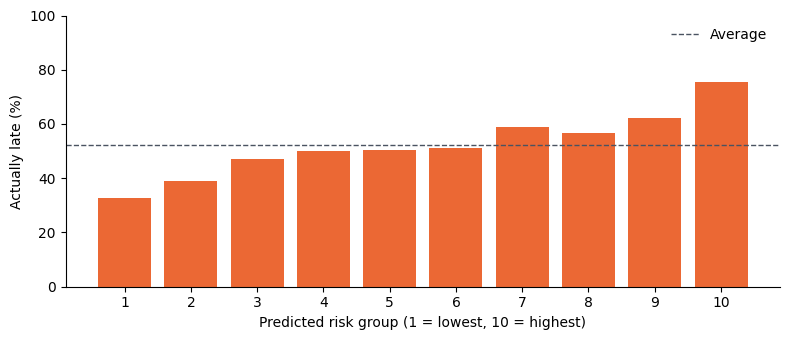

In [10]:
dec = pd.DataFrame({"p": p_gbm, "late": test["late"].values})
dec["risk_decile"] = pd.qcut(dec["p"], 10, labels=range(1, 11))
tab = dec.groupby("risk_decile", observed=True).agg(applications=("late", "size"),
                                                    predicted=("p", "mean"), actually_late=("late", "mean"))
display(tab.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(tab.index.astype(str), tab["actually_late"] * 100, color="#eb6834")
ax.axhline(test["late"].mean() * 100, color="#4a5361", ls="--", lw=1, label="Average")
ax.set_xlabel("Predicted risk group (1 = lowest, 10 = highest)")
ax.set_ylabel("Actually late (%)")
ax.set_ylim(0, 100); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

The highest-risk tenth is late about three-quarters of the time. The lowest-risk tenth is late about a third of the time. That's good enough to flag applications for attention, but not to promise anyone a date.

**Calibration:** LightGBM's probabilities run a bit high in the test years, because 2024–25 was less often late than 2021–23. To use the probabilities at face value, recalibrate them on recent data.

## 6 · What drives lateness

**Permutation importance:** shuffle one feature at a time in the test set and see how much the AUC drops. A bigger drop means the model relies on that feature more.

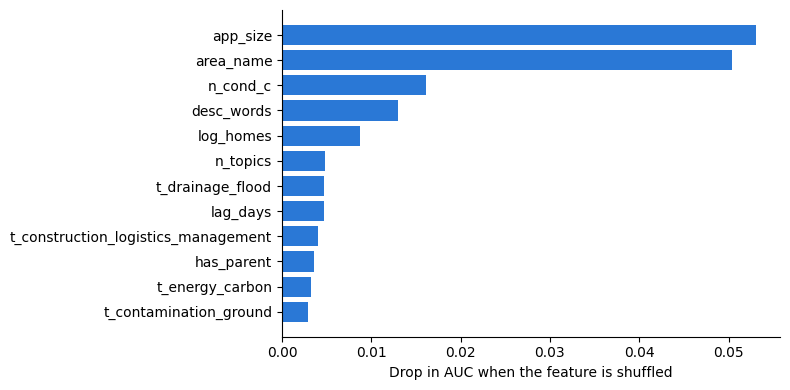

In [11]:
pi = permutation_importance(gbm, Xte, test["late"], scoring="roc_auc", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=CAT + NUM).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color="#2a78d6")
ax.set_xlabel("Drop in AUC when the feature is shuffled")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Bundling (`n_cond_c`) is the strongest feature after application size and borough. Drainage and construction logistics are the topics that matter most, which matches the page.

### Bundling, with everything else held constant

The page shows that applications bundling many conditions are late more often, but bigger schemes also bundle more. The logistic model lets us change **only** the number of conditions, keeping each application's borough, size, topics and everything else as it was, and see how the average predicted risk moves.

In [12]:
X = test[CAT + NUM].fillna(medians)
rows = []
for k in [1, 2, 3, 4, 5, 7]:
    Xk = X.copy(); Xk["n_cond_c"] = k
    rows.append({"conditions bundled": k, "predicted late (all else equal)": logit.predict_proba(Xk)[:, 1].mean()})
effect = pd.DataFrame(rows).set_index("conditions bundled")
effect["actually late (raw)"] = test.groupby(test["n_cond"].clip(upper=7))["late"].mean()
effect.style.format("{:.0%}")

,predicted late (all else equal),actually late (raw)
conditions bundled,,
1,54%,50%
2,60%,56%
3,64%,62%
4,69%,64%
5,73%,70%
7,81%,88%


Going from one condition to seven raises the predicted chance of being late by roughly **25 percentage points**, even after holding borough, scheme size and topic constant. This backs up the bundling finding on the page: bundling is linked to lateness in its own right, not just through scheme size.

The logistic model treats the effect of each extra condition as a straight line. The raw rates in the right-hand column show the real pattern is similar.

## 7 · What this does and doesn't show

**Does show**
- Lateness is **partly predictable** on day one (AUC about 0.62 against 0.50 for guessing). The model's highest-risk tenth is late about twice as often as its lowest-risk tenth.
- **Application size and borough** are the two biggest factors. PlanIt's Small/Medium/Large label (`app_size`) and the borough matter far more than what the conditions are about. How a council works matters more than what is being asked.
- **Bundling** many conditions is linked to lateness even with other factors held constant.

**Doesn't show**
- **Cause and effect.** These are associations. Developers who bundle may also differ in other ways the data doesn't capture.
- **Most of the variation.** The key drivers are missing from the data: officer caseload, how complete the submission is, consultee responses (such as the drainage authority), and agreed extensions.
- **Every borough.** Several boroughs barely appear in the data, so the model knows little about them.
- **That `app_size` is safe.** It comes from PlanIt, not the council, and almost all of the model's gain over the borough baseline depends on it: without it, AUC falls from 0.63 to 0.60. If PlanIt works it out partly from things that build up after submission, it would leak some of the answer. Check how PlanIt defines it before relying on the model.

**Next steps if you want to push it further**
1. Recalibrate the probabilities on 2024 data before quoting them.
2. Predict **days to decision** with a survival model, so that 57 days and 300 days aren't treated the same.
3. Add the refused / part-approved outcome as a second target.

## 8 · Reading the description with JEV

### Why

The description features above (topics, number of conditions, pre-start flag) come from **keyword matching** in `analysis.py`. But most descriptions have two parts: the **request** ("discharge of condition 13 (construction method statement)") and a **copy of the original permission** ("…erection of 41 flats with cycle storage, refuse storage and landscaping"). The keyword tagger reads both, so it often tags the **scheme** rather than the condition being signed off.

### How the JEV process works

1. **Model:** Jev (`~typesafe/jev-latest`, served by TypeSafe through OpenRouter's **decisions** API at `https://openrouter.ai/api/alpha/decisions`). Jev doesn't write free text. It answers narrow, **typed questions** about a piece of "state", and the code decides what to do with the answers.
2. **State:** one short line of context (the two parts of a description, and to ignore the copied permission text), then the description itself.
3. **Questions**, all asked in one request per description:
   - **16 yes/no questions, one per topic** (type `noul`): "Do any of the conditions being discharged cover drainage, SuDS, flood risk…?" Each comes back as a **probability from 0 to 1**. A topic counts if it's 0.5 or more. The definitions match the keyword tagger, so both mean the same thing.
   - **Number of conditions** (type `choice`): 1, 2, … 9, 10+ or "can't tell".
   - **Topic stated?** (`noul`): does the request say what the conditions cover, or only give numbers?
   - **Pre-start?** (`choice`): yes, no or not stated.
4. **Cache:** 8 requests run in parallel, and every answer is saved to `outputs/jev_topics.jsonl`, so reruns only label what's missing. A spending cap stops the run if costs run over.
5. **Cost:** about $0.08 per 1,000 descriptions, roughly $1.40 for all 17,079, at about 25 descriptions per second.

An earlier run went through `typesafe/jev-router`, which forwards each request to another model (DeepSeek, in practice). It covered 12,560 descriptions before the account ran out of credit. Jev agreed with it on the topics 84% of the time and on the condition count 99% of the time.

The script is `src/conditions_queue/classify_jev.py`. Here is exactly what it sends for each description:

In [13]:
import json
from conditions_queue import classify_jev as jev
print(f"Endpoint: {jev.URL}\nModel: {jev.MODEL}\n")
print("State, line 1:", jev.CONTEXT, "\nState, line 2: 'Description: <the application description>'\n")
print("Questions (first topic shown; the other 15 follow the same pattern):")
first = next(iter(jev.QUESTIONS))
print(json.dumps({first: jev.QUESTIONS[first], **{k: jev.QUESTIONS[k] for k in ['n_conditions', 'topic_stated', 'pre_commencement']}}, indent=1))

Endpoint: https://openrouter.ai/api/alpha/decisions
Model: ~typesafe/jev-latest

State, line 1: A UK planning application to discharge (sign off) planning conditions. The description first says which condition(s) are being discharged, often with a short name in brackets. It then usually copies the ORIGINAL permission's description (e.g. 'for erection of 41 flats with cycle storage and landscaping'). Judge only the conditions being discharged and ignore the copied permission text. 
State, line 2: 'Description: <the application description>'

Questions (first topic shown; the other 15 follow the same pattern):
{
 "t0": {
  "type": "noul",
  "instructions": "Do any of the conditions being discharged cover accessible or wheelchair housing (M4(2), M4(3)), accessibility?",
  "criteria": {
   "true": "At least one condition being discharged covers this",
   "false": "None of the conditions being discharged covers this (mentions in the copied permission text don't count)"
  }
 },
 "n_condition

In [14]:
# Set to True to label any descriptions not yet in outputs/jev_topics.jsonl.
# Needs OPENROUTER_API_KEY (or a .env file at the repo root). Costs about $0.08 per 1,000 descriptions.
RUN_JEV = False
if RUN_JEV:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "conditions_queue.classify_jev", "--workers", "8", "--max-cost", "3"],
                   cwd=paths.ROOT / "src", check=True)

### One description, start to finish

The saved answer for one application: Jev's probability for each topic, then the labels the code keeps.

In [15]:
import textwrap
jev_saved = {r["name"]: r for r in map(json.loads, open(paths.OUTPUTS / "jev_topics.jsonl"))}
example = next(n for n in d["name"] if n in jev_saved and len(jev_saved[n]["topics"]) >= 2)
print(textwrap.fill(d.loc[d["name"] == example, "description"].iloc[0], 140), "\n")
r = jev_saved[example]
for t, p in sorted(r["topic_probs"].items(), key=lambda kv: -kv[1])[:6]:
    print(f"  {p:5.2f}  {t}")
print(f"\nKept topics: {r['topics']} · conditions: {r['n_conditions']} · topic stated: {r['topic_stated']} · pre-start: {r['pre_commencement']}")

Formal Application Description : Approval of details (Access, Appearance, Landscaping, Layout and Scale), relating to Plots A, B and C of
outline planning permission ref: 21/01808/OUTALL comprising erection of buildings to deliver residential dwellings (Class C3), and ancillary
residential floorspace and/or non-residential floorspace; delivery of new public open space and communal open space, including children’s
play space, new public realm, landscaping works and new lighting; car and cycle parking spaces together with associated highways and
utilities works incidental to the proposed development, including temporary highways works. (Phase 1 Development). Further Explanation (not
forming part of the formal description of development set out above): Approval of details (Access, Appearance, Landscaping, Layout and
Scale), relating to Plots A, B and C of outline planning permission ref: 21/01808/OUTALL comprising erection of buildings (ranging in
heights from 6 to 19 storeys) to deliver 

### Load JEV's labels and compare with the keyword tags

In [16]:
import textwrap
from conditions_queue.features import add_jev_features, JEV_COLS, NUM_JEV, KEYWORD_TEXT_COLS, LABELS, TOPICS as TOPIC_NAMES, slug as tslug
dj, jev_coverage = add_jev_features(d)
print(f"Applications with a JEV label: {jev_coverage:.1%}")

topic_rates = pd.DataFrame({
    "keyword tagger %": [100 * dj[tslug(t)].mean() for t in TOPIC_NAMES],
    "JEV %": [100 * dj["jev_" + tslug(t)[2:]].mean() for t in TOPIC_NAMES],
}, index=TOPIC_NAMES).sort_values("keyword tagger %", ascending=False)
display(topic_rates.round(0))

ex = dj[dj["jev_topics"].notna()].sample(5, random_state=4)
for r in ex.itertuples():
    kw = [t for t in TOPIC_NAMES if getattr(r, tslug(t))]
    print(textwrap.shorten(r.description, 230))
    print(f"   keyword: {kw} · {r.n_cond} condition(s)")
    print(f"   JEV:     {r.jev_topics} · {r.jev_n_cond_c:.0f} condition(s)\n")

Applications with a JEV label: 100.0%


,keyword tagger %,JEV %
"Waste, cycle & parking",77.0,18.0
Landscaping & trees,61.0,18.0
Materials & design detail,20.0,18.0
Piling & structure,20.0,4.0
Energy & carbon,18.0,12.0
Construction logistics / management,10.0,17.0
Boundary & lighting,10.0,6.0
Drainage & flood,10.0,10.0
"Noise, vibration & air",9.0,11.0
Highways & travel,8.0,9.0


Details pursuant to conditions 7 (construction method statement) and 8 (cycle and refuse storage) of Full Planning Permission reference 20/1834 dated 15 October, 2020, for Conversion of the single dwellinghouse into three [...]
   keyword: ['Construction logistics / management', 'Landscaping & trees', 'Materials & design detail', 'Piling & structure', 'Waste, cycle & parking'] · 2 condition(s)
   JEV:     ['Construction logistics / management', 'Waste, cycle & parking'] · 2 condition(s)

Details of condition 19 (Written Scheme of Investigation) submitted pursuant planning permission 00607/56-57/P12 dated 25/04/2022 for erection of a single storey residential dwelling with associated access, landscaping, [...]
   keyword: ['Archaeology & heritage', 'Landscaping & trees', 'Waste, cycle & parking'] · 1 condition(s)
   JEV:     ['Archaeology & heritage', 'Contamination & ground'] · 1 condition(s)

Bird and bat box details required by condition 17 of permission ref 2020/4667/P dated 27/07/2

### Refit both models with JEV's description features

Same applications, same time split, same settings. The only change is that the keyword description features (`n_cond_c`, `n_topics`, `any_precommencement` and the 16 topic flags) are swapped for JEV's versions. LightGBM is fitted with 5 random seeds, so we can tell a real gain from noise.

In [17]:
train_j, test_j = dj[dj["start_date"] < "2024-01-01"].copy(), dj[dj["start_date"] >= "2024-01-01"].copy()
NO_TEXT = [c for c in NUM if c not in KEYWORD_TEXT_COLS]
med_j = train_j[NUM_JEV].median()

def fit_logit(num):
    m = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), num)]),
                      LogisticRegression(max_iter=2000, C=0.5))
    meds = train_j[num].median()
    m.fit(train_j[CAT + num].fillna(meds), train_j["late"])
    return m, meds

def gbm_auc(num, seeds=5):
    Xtr_, Xte_ = train_j[CAT + num].copy(), test_j[CAT + num].copy()
    for c in CAT:
        Xtr_[c] = Xtr_[c].astype("category"); Xte_[c] = pd.Categorical(Xte_[c], categories=Xtr_[c].cat.categories)
    aucs, last = [], None
    for s in range(seeds):
        last = lgb.LGBMClassifier(**{**gbm.get_params(), "random_state": s}).fit(Xtr_, train_j["late"])
        aucs.append(roc_auc_score(test_j["late"], last.predict_proba(Xte_)[:, 1]))
    return np.mean(aucs), np.std(aucs), last, Xte_

jev_rows = []
for label, num in [("No description features", NO_TEXT), ("Keyword description features", NUM), ("JEV description features", NUM_JEV)]:
    lm, meds = fit_logit(num)
    lauc = roc_auc_score(test_j["late"], lm.predict_proba(test_j[CAT + num].fillna(meds))[:, 1])
    gmean, gstd, gmodel, gX = gbm_auc(num)
    jev_rows.append({"description features": label, "Logistic AUC": lauc, "LightGBM AUC": gmean, "LightGBM ± (5 seeds)": gstd})
    if label.startswith("JEV"):
        logit_jev, med_jev, gbm_jev, Xte_jev = lm, meds, gmodel, gX
jev_compare = pd.DataFrame(jev_rows).set_index("description features")
jev_compare.round(3)

,Logistic AUC,LightGBM AUC,LightGBM ± (5 seeds)
description features,,,
No description features,0.593,0.596,0.001
Keyword description features,0.615,0.627,0.002
JEV description features,0.623,0.636,0.001


### Bundling with JEV's condition counts, everything else held constant

In [18]:
Xb = test_j[CAT + NUM_JEV].fillna(med_jev)
bund_rows = []
for k in [1, 2, 3, 4, 5, 7]:
    Xk = Xb.copy(); Xk["jev_n_cond_c"] = k
    bund_rows.append({"conditions bundled": k, "predicted late (JEV count)": logit_jev.predict_proba(Xk)[:, 1].mean(),
                      "actually late (JEV count)": test_j.loc[test_j["jev_n_cond_c"].clip(upper=7) == k, "late"].mean(),
                      "applications": int((test_j["jev_n_cond_c"].clip(upper=7) == k).sum())})
jev_bundling = pd.DataFrame(bund_rows).set_index("conditions bundled")
jev_bundling.style.format({"predicted late (JEV count)": "{:.0%}", "actually late (JEV count)": "{:.0%}", "applications": "{:,}"})

,predicted late (JEV count),actually late (JEV count),applications
conditions bundled,,,
1,53%,50%,"3,926"
2,57%,53%,786
3,62%,58%,359
4,66%,61%,209
5,70%,68%,114
7,78%,78%,100


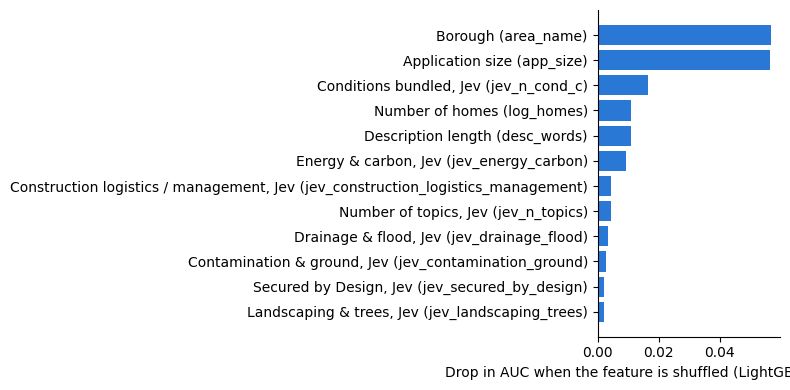

In [19]:
pi_j = permutation_importance(gbm_jev, Xte_jev, test_j["late"], scoring="roc_auc", n_repeats=3, random_state=0)
imp_j = pd.Series(pi_j.importances_mean, index=CAT + NUM_JEV).sort_values(ascending=False).head(12)
imp_j.index = [LABELS.get(i, i) for i in imp_j.index]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp_j.index[::-1], imp_j.values[::-1], color="#2a78d6")
ax.set_xlabel("Drop in AUC when the feature is shuffled (LightGBM with JEV features)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

**Reading this:**
- **The description is where most of the extra predictive power comes from.** Without any description features, LightGBM barely beats each borough's late rate (AUC 0.596 against 0.595). Keyword features lift it to 0.627. Jev's features lift it to **0.636**, the best score of any model here, and the seed-to-seed noise is only ±0.001.
- **Jev's labels beat the keyword ones in both models** (logistic 0.615 → 0.623, LightGBM 0.627 → 0.636). Reading only the conditions being signed off, rather than the copied scheme text, gives the models a cleaner signal.
- **Bundling still matters with Jev's more accurate counts.** All else equal, the predicted chance of being late rises from 53% for one condition to 78% for seven or more, and the actual late rates follow the same path.
- **Pre-start is almost never written into the description** (Jev found it in well under 1%), so that feature adds little. The keyword version only guessed it from the topic.

## 9 · Summary

- **Why predict this:** over half of London's condition sign-offs miss the 8-week deadline, and many have to be cleared before building can start. Flagging the ones likely to run late on the day they're submitted lets councils prioritise them, and lets developers plan start dates around a realistic sign-off date.
- **Target:** `late` = decided after 56 days, or still undecided past that point (56% of 16,284 applications).
- **How well it works:** the best model (LightGBM with Jev's description features) reaches an AUC of 0.636, against 0.595 for each borough's late rate and 0.5 for a coin flip. Its highest-risk tenth is late about twice as often as its lowest-risk tenth. That's useful for triage, but not for promising individual outcomes.
- **The description matters:** without description features, the model barely beats the borough baseline (0.596). Reading the description lifts AUC by 0.03–0.04, and Jev's labels do better than the keyword tagger's.
- **Biggest drivers:** application size, borough, what the conditions are about, and how many are bundled. Each extra condition bundled raises the chance of being late, even with everything else held constant.

## 10 · Save results for the UI

In [20]:
import json
def records(df):
    return json.loads(df.reset_index().to_json(orient="records"))
ui = {
    "notebook": "02_late_model.ipynb",
    "n_applications": int(len(d)), "late_share": float(d["late"].mean()),
    "train": {"n": int(len(train)), "late_share": float(train["late"].mean())},
    "test": {"n": int(len(test)), "late_share": float(test["late"].mean())},
    "scores": records(pd.DataFrame(results).T.rename_axis("model")),
    "risk_deciles": records(tab.rename_axis("decile")),
    "importance_keyword_gbm": records(imp.rename("auc_drop").rename_axis("feature").to_frame()),
    "bundling_keyword": records(effect.rename_axis("conditions")),
    "jev": {"coverage": float(jev_coverage), "compare": records(jev_compare), "bundling": records(jev_bundling),
            "importance_gbm": records(imp_j.rename("auc_drop").rename_axis("feature").to_frame()),
            "topic_rates": records(topic_rates.rename_axis("topic"))},
}
with open(paths.OUTPUTS / "ui_late_model.json", "w") as f:
    json.dump(ui, f, indent=1)
print("wrote outputs/ui_late_model.json")

wrote outputs/ui_late_model.json
